# Unsupervised Learning to Identify Patterns in Cardiovascular Disease Using K-Means Clustering

This project follows on from my previous project (Predicting the Likelihood of a Heart Attack or Stroke Using a Random Forest Model with XGBoost). It uses the same synthetic dataset (https://www.arc-wx.nihr.ac.uk/data-sets) and attempts to use unsupervised learning approaches to identify relationships between various risk factors for cardiovascular disease. This project uses the 'cleaned' form of the dataset from the previous project - for an explanation of the data cleaning process please refer to this previous project.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('cvd_synthetic_dataset_v0.2_cleaned.csv')
# the first few entries to illustrate the dataset
print(df.head())

   Unnamed: 0  patient_id  gender  age  body_mass_index  smoker  \
0           0  PT00085957       1   54             25.0       0   
1           1  PT00093111       0   31             27.1       0   
2           2  PT00058456       0   50             31.3       0   
3           3  PT00016352       0   61             30.0       0   
4           4  PT00060611       1   67             32.6       0   

   systolic_blood_pressure  hypertension_treated  \
0                    161.0                     0   
1                    121.0                     0   
2                    130.0                     0   
3                    165.0                     0   
4                    166.0                     0   

   family_history_of_cardiovascular_disease  atrial_fibrillation  \
0                                         1                    0   
1                                         0                    0   
2                                         0                    0   
3           

The KMeans algorithm from scikit-learn was chosen as the unsupervised learning algorithm for this project. This algorithm assigns a specified number of cluster centroids (*k*), then assigns datapoints to the nearest centroid via the euclidean distance. It then iteratively adjusts the location of the centroid so as to reduce the mean distane from the centroid for all points in the specified cluster, until convergence.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
# as the other variables are all discrete/categorical, they are not optimal for clustering
cluster_features = ['age', 'body_mass_index', 'systolic_blood_pressure', 'forced_expiratory_volume_1']
# scaling data between 0-1 to avoid larger values (e.g. SBP) overwhelming smaller ones e.g. BMI
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df[cluster_features])

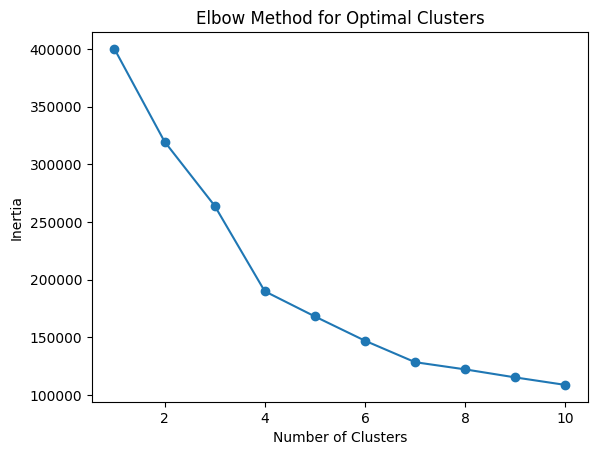

In [ ]:
# inertia measures the sum of squared distances of samples to their closest cluster center
inertia = []
# graphing the inertia as the number of clusters increases
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=1)
    kmeans.fit(scaled_data)
    inertia.append(kmeans.inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.title('Elbow Method for Optimal Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.show()

The elbow method is a heuristic within clustering algorithms used to determine the optimal number of clusters. The elbow point is the point at which the rate of decrease of inertia sharply flattens, and is generally thought that after this point an increasing number of clusters is less likely to provide value (and more prone to overfitting). In this case there is not necessarily a drastic decrease, but the graph shows diminishing returns after 4 clusters.

In [ ]:
# running the k-means algorithm with 4 clusters as per the elbow method
kmeans = KMeans(n_clusters=4, random_state=1)
df['patient_cluster'] = kmeans.fit_predict(scaled_data)

# we can see if the clusters vary in terms of the number of cardiovascular events
cluster_validation = df.groupby('patient_cluster')['heart_attack_or_stroke_occurred'].mean()
print(f"Percentage of patients with cardiovascular events in each cluster: {cluster_validation*100}")

Percentage of patients with cardiovascular events in each cluster: patient_cluster
0     1.677852
1     2.130751
2    12.908195
3    11.649519
Name: heart_attack_or_stroke_occurred, dtype: float64


As per the elbow method I have chosen four clusters for the model to identify. When calculating the proportion of patients in each cluster who have suffered a cardiovascular event, we can see that the model has essentially identified two 'healthy' clusters (with prevalence of cardiovascular events ~1-2%) and two 'unhealthy' clusters (prevalence ~12-13%). This is supported further by the fact that the prevalence of cardiovascular events across the whole cohort was around 6.6% (below).

In [ ]:
print(df['heart_attack_or_stroke_occurred'].mean()*100)

6.612


We can view the number of patients in each cluster:

In [ ]:
print(pd.Series(kmeans.labels_).value_counts())

1    41300
2    39595
0    16092
3     3013
Name: count, dtype: int64


As well as the mean of the included variables in each cluster in tabular form:

In [ ]:
print(df.groupby('patient_cluster')[['age', 'body_mass_index', 'systolic_blood_pressure', 'forced_expiratory_volume_1']].mean())

                       age  body_mass_index  systolic_blood_pressure  \
patient_cluster                                                        
0                32.026286        21.375839               124.342282   
1                37.795424        28.412155               120.926295   
2                61.682258        27.822791               141.372724   
3                56.552605        27.395685               132.634915   

                 forced_expiratory_volume_1  
patient_cluster                              
0                                 93.399081  
1                                 93.329183  
2                                 92.731320  
3                                 45.540055  


Now that we have identified the four clusters, it is useful to visualise them against each other using a pairplot:

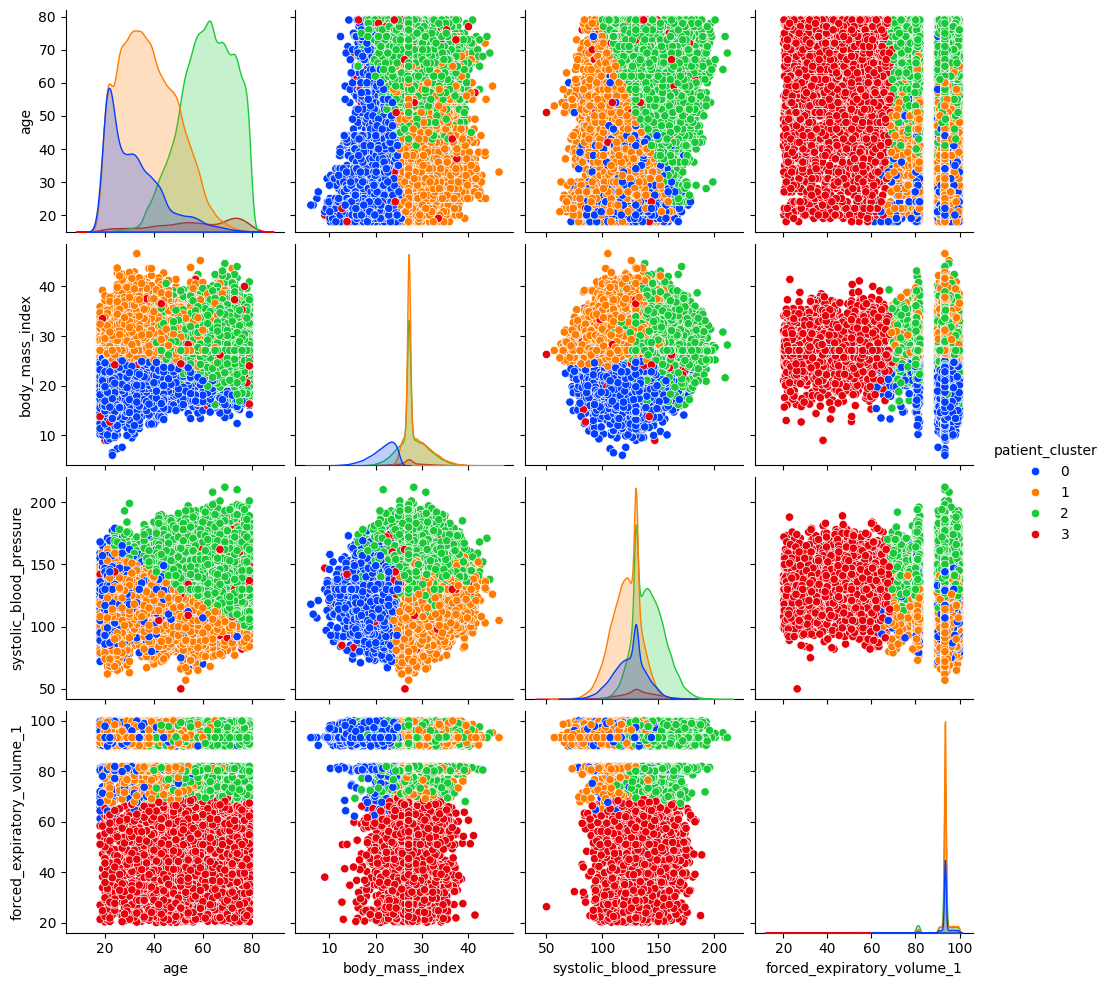

In [ ]:
import seaborn as sns
# adding the column headings as labels to the dataframe for plotting
df['patient_cluster'] = kmeans.labels_
# plotting each variable against the other to visualise the clusters
sns.pairplot(df, vars=cluster_features, hue='patient_cluster', palette='bright')
plt.show()

And a heatmap:

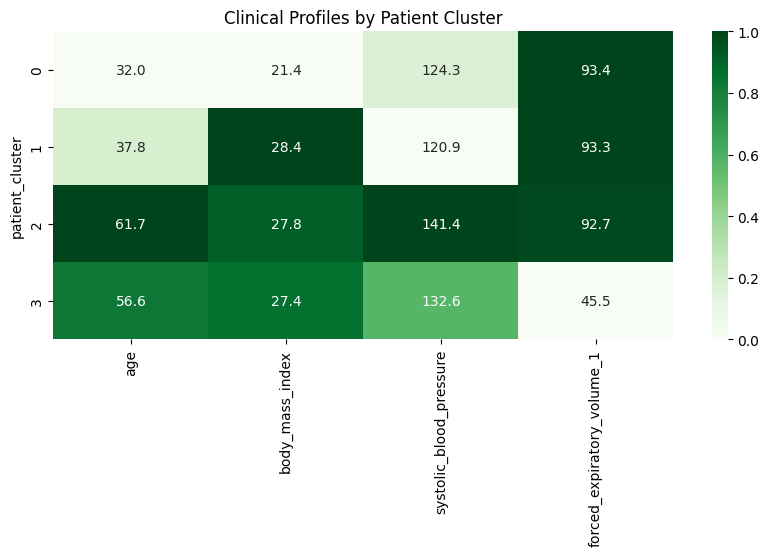

In [ ]:
cluster_means = df.groupby('patient_cluster')[['age', 'body_mass_index', 'systolic_blood_pressure', 'forced_expiratory_volume_1']].mean()

# scaling each cluster by 0-1 for comparability but the values will be printed inside the boxes regardless
cluster_means_scaled = (cluster_means - cluster_means.min()) / (cluster_means.max() - cluster_means.min())

plt.figure(figsize=(10, 4))
sns.heatmap(cluster_means_scaled, annot=cluster_means, fmt=".1f", cmap="Greens")
plt.title("Clinical Profiles by Patient Cluster")
plt.show()

These plots can indicate patterns about the possible patient groups:
*   Cluster 0 indicates generally healthy patients all around - those who have low BMI, normal SBP and good lung capacity, and that these people generally tend to be younger
*   Cluster 1 indicates that there is a separate group of relatively young people, with normal SBP, preserved lung function and a lower-than-average rate of cardiovascular events (across the whole population), but who are overweight.
*   Cluster 3 comprises generally older people, with high BMI and blood pressure but normal lung function. As this group had a high rate of cardiovascular events, it indicates that there is a large group of older people with metabolic risk factors for heart attacks and strokes.
*   Finally, Cluster 4 also comprises relatively older people with high BMI, but with upper-end-of-normal BP and a drastically reduced FEV1. This group also had high rates of heart attacks/strokes, suggesting that there exists a separate patient group with very poor lung function, who also tend to be older (but younger than cluster 3) and overweight, and that these patients have a high cardiovascular risk. Clinically this could represent patients with COPD or other respiratory diseases.

Overall, this project highlights the concept of multimodal risk in healthcare - adverse events in healthcare can be influenced by many different risk factors, several of which can be often associated together (e.g. SBP, BMI, age), but also strongly influenced by specific risk factors which have the power to dominate health outcomes (such as the presence of significant respiratory disease).

This project has several limitations - firstly, the use of imputation to fill in the missing data (as documented during the cleaning process in my previous project) can cast doubts as to the practical application of this data. For BMI and SBP, where there were ~70,000 and ~90,000 datapoints respectively (out of 100,000 patients), this may be less pertinent of an issue than in the case of FEV1, where only ~30,000 patients had a reported FEV1, leaving around ~70,000 with the imputed median. As this model identified an entire cluster which was dominated by having a low FEV1, in order to test if these patterns hold in a real-world scenario it may be necessary to devise strategies to handle the missing data. This could include repeating the clustering algorithm with only the records that were complete, although testing would need to ensure these records are not significantly different in their demographics from the incomplete rows.

Furthermore, the choice to use 4 clusters was a personal decision which was loosely based on the elbow method, despite there still being improvements in inertia with larger numbers of clusters. Optimising a model in terms of increasing clusters requires a precise balance between gaining insights and limiting overfitting - repeating this model with n=5, n=6 or even n=7 clusters would be useful to visualise the relationships between the variables in each cluster, but only with the clinical experience to suggest if there may be underlying scientific or epidemiological explanations for the relationships.